# AI-Generated Content Detection Pattern

This project explores whether human-written and ChatGPT-generated answers can be told apart using simple text statistics. We use the HC3 (Human ChatGPT Comparison Corpus) dataset, cleaning and restructuring it into a balanced set of labeled answers for further exploratory analysis.

## 1. Data Loading

We load the raw HC3 dataset (`raw_dataset.csv`) into a DataFrame and take a quick look at its structure before any cleaning.

In [1]:
import pandas as pd
import json
import matplotlib.pyplot as plt

In [2]:
raw_df = pd.read_csv("../Dataset/raw_dataset.csv")
raw_df.head()

,question,human_answers,chatgpt_answers,index,source
0,"Why is every book I hear about a "" NY Times # ...","[""Basically there are many categories of \"" Be...","[""There are many different best seller lists t...",NaN,reddit_eli5
1,"If salt is so bad for cars , why do we use it ...","[""salt is good for not dying in car crashes an...","[""Salt is used on roads to help melt ice and s...",NaN,reddit_eli5
2,Why do we still have SD TV channels when HD lo...,"[""The way it works is that old TV stations got...","[""There are a few reasons why we still have SD...",NaN,reddit_eli5
3,Why has nobody assassinated Kim Jong - un He i...,"[""You ca n't just go around assassinating the ...","[""It is generally not acceptable or ethical to...",NaN,reddit_eli5
4,How was airplane technology able to advance so...,"[""Wanting to kill the shit out of Germans driv...","[""After the Wright Brothers made the first pow...",NaN,reddit_eli5


In [3]:
# Create Raw dataframe - Back up 

df = raw_df.copy()

## 2. Data Cleaning

We check for nulls, drop the unused `index` column, remove duplicate rows, and review the `source` categories to understand the composition of the dataset.

In [4]:
df.isnull()

,question,human_answers,chatgpt_answers,index,source
0,False,False,False,True,False
1,False,False,False,True,False
2,False,False,False,True,False
3,False,False,False,True,False
4,False,False,False,True,False
...,...,...,...,...,...
24317,False,False,False,True,False
24318,False,False,False,True,False
24319,False,False,False,True,False
24320,False,False,False,True,False


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24322 entries, 0 to 24321
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   question         24322 non-null  object 
 1   human_answers    24322 non-null  object 
 2   chatgpt_answers  24322 non-null  object 
 3   index            2521 non-null   float64
 4   source           24322 non-null  object 
dtypes: float64(1), object(4)
memory usage: 950.2+ KB


In [6]:
df.isnull().sum()

question               0
human_answers          0
chatgpt_answers        0
index              21801
source                 0
dtype: int64

In [7]:
df_not_null = df[df["index"].notnull()]

df_not_null

,question,human_answers,chatgpt_answers,index,source
1607,Can someone explain to me what a tax bracket i...,"[""A tax bracket says the percentage of your in...","[""A tax bracket is a range of income that is t...",0.0,reddit_eli5
1608,World War 2 . Explain like I 'm 5 . Who what w...,"[""After WW1 , Germany was incredibly poor due ...","[""World War 2 was a big war that happened a lo...",1.0,reddit_eli5
1609,"Ubuntu , I know it 's a Linux kernel . That 's...","[""First off , it 's a Linux distribution based...","[""Ubuntu is a type of operating system, which ...",2.0,reddit_eli5
1610,LI5 : Can someone explain how someone can embe...,"[""Embezzling can happen many different ways . ...","[""Embezzlement is the act of stealing money or...",3.0,reddit_eli5
1611,Can someone please explain to me how WiFi work...,"[""In a nutshell , the router is plugged into t...","[""Sure! Here's a simple explanation of how WiF...",4.0,reddit_eli5
...,...,...,...,...,...
4123,Why we hate Richard Nixon . I 'm not American ...,"[""Nixon did n't start the Viet Nam War , That ...","[""Richard Nixon was the President of the Unite...",4995.0,reddit_eli5
4124,Cloud Computing . I do n't really grasp the me...,"[""Cloud computing means different things to di...","[""Sure! Cloud computing is a way to use the in...",4996.0,reddit_eli5
4125,"At what point is someone an addict Alcohol , d...","[""When it starts to seriously affect your abil...","[""An addict is someone who is unable to stop u...",4997.0,reddit_eli5
4126,Why do bees die when they lose their stingers ...,"[""Most bees will never reproduce , so sacrific...","[""Bees die when they lose their stingers becau...",4998.0,reddit_eli5


In [8]:
df = df.drop(columns=["index"])
df.head()

,question,human_answers,chatgpt_answers,source
0,"Why is every book I hear about a "" NY Times # ...","[""Basically there are many categories of \"" Be...","[""There are many different best seller lists t...",reddit_eli5
1,"If salt is so bad for cars , why do we use it ...","[""salt is good for not dying in car crashes an...","[""Salt is used on roads to help melt ice and s...",reddit_eli5
2,Why do we still have SD TV channels when HD lo...,"[""The way it works is that old TV stations got...","[""There are a few reasons why we still have SD...",reddit_eli5
3,Why has nobody assassinated Kim Jong - un He i...,"[""You ca n't just go around assassinating the ...","[""It is generally not acceptable or ethical to...",reddit_eli5
4,How was airplane technology able to advance so...,"[""Wanting to kill the shit out of Germans driv...","[""After the Wright Brothers made the first pow...",reddit_eli5


In [9]:
df.duplicated().sum()

np.int64(509)

In [10]:
df = df.drop_duplicates()

In [11]:
df.shape

(23813, 4)

In [12]:
df["source"].value_counts()

source
reddit_eli5    16603
finance         3933
medicine        1248
open_qa         1187
wiki_csai        842
Name: count, dtype: int64

In [13]:
df["source"].nunique()

5

In [14]:
df["human_answers"] = df["human_answers"].apply(json.loads)
df["chatgpt_answers"] = df["chatgpt_answers"].apply(json.loads)

In [15]:
print("Empty human lists:", (df["human_answers"].str.len() == 0).sum())
print("Empty ChatGPT lists:", (df["chatgpt_answers"].str.len() == 0).sum())

print(df["human_answers"].str.len().value_counts())
print(df["chatgpt_answers"].str.len().value_counts())

Empty human lists: 0
Empty ChatGPT lists: 450
human_answers
3    16603
1     7210
Name: count, dtype: int64
chatgpt_answers
1    21530
3     1203
2      630
0      450
Name: count, dtype: int64


## 3. Restructuring: One Row per Answer

Each row currently holds a *list* of human answers and a *list* of ChatGPT answers for one question. We explode these lists so that every row represents a single answer with a `label` (0 = Human, 1 = ChatGPT), then remove null and blank answers.

In [16]:
human = df[["question", "source", "human_answers"]].explode("human_answers")
human = human.rename(columns={"human_answers": "answer"})
human["label"] = 0

ai = df[["question", "source", "chatgpt_answers"]].explode("chatgpt_answers")
ai = ai.rename(columns={"chatgpt_answers": "answer"})
ai["label"] = 1

data = pd.concat([human, ai], ignore_index=True)

In [17]:
print(data.groupby("label")["answer"].apply(lambda s: s.isnull().sum()))

label
0      0
1    450
Name: answer, dtype: int64


In [18]:
data = data.dropna(subset=["answer"])
data["answer"] = data["answer"].str.strip()

print("Blank texts per label:")
print(data[data["answer"] == ""]["label"].value_counts())

data = data[data["answer"] != ""]

Blank texts per label:
label
1    18
Name: count, dtype: int64


In [19]:
print(data.shape)
print(data["label"].value_counts())
print(data.isnull().sum())

(83400, 4)
label
0    57019
1    26381
Name: count, dtype: int64
question    0
source      0
answer      0
label       0
dtype: int64


## 4. Exploratory Data Analysis (EDA)

With one answer per row, we compute word counts and writing-style features (sentence count, average sentence length, first-person usage, question marks) to see how Human and ChatGPT answers differ.

In [20]:
data["word_count"] = data["answer"].str.split().str.len()
print(data.groupby("label")["word_count"].describe())

         count        mean         std  min    25%    50%    75%     max
label                                                                   
0      57019.0  133.952437  163.736084  1.0   42.0   83.0  163.0  7904.0
1      26381.0  173.059437   61.605878  1.0  130.0  174.0  212.0   639.0


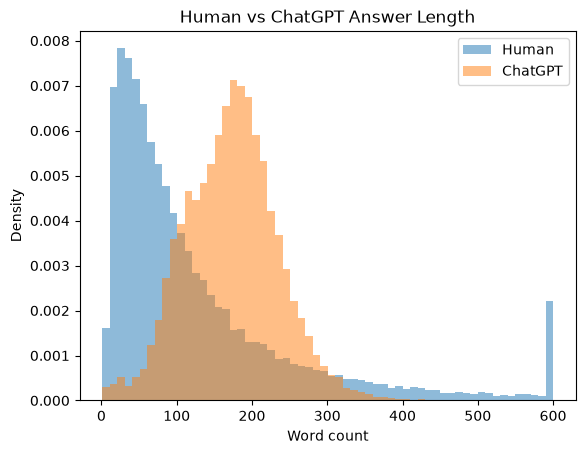

In [21]:
plt.hist(data[data["label"] == 0]["word_count"].clip(upper=600), bins=60, alpha=0.5, label="Human", density=True)
plt.hist(data[data["label"] == 1]["word_count"].clip(upper=600), bins=60, alpha=0.5, label="ChatGPT", density=True)
plt.xlabel("Word count")
plt.ylabel("Density")
plt.legend()
plt.title("Human vs ChatGPT Answer Length")
plt.savefig("../Visualizations/distribution_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
data["sentence_count"] = data["answer"].str.count(r"[.!?]+") + 1
data["avg_sentence_len"] = data["word_count"] / data["sentence_count"]
data["first_person"] = data["answer"].str.count(r"\b(I|me|my)\b")
data["question_marks"] = data["answer"].str.count(r"\?")

print(data.groupby("label")[["word_count", "sentence_count", "avg_sentence_len",
                             "first_person", "question_marks"]].mean())

       word_count  sentence_count  avg_sentence_len  first_person  \
label                                                               
0      133.952437        7.751925         16.148683      0.946088   
1      173.059437        9.149312         19.108071      0.207763   

       question_marks  
label                  
0            0.224785  
1            0.070467  


In [23]:
print(data.isnull().sum())

question            0
source              0
answer              0
label               0
word_count          0
sentence_count      0
avg_sentence_len    0
first_person        0
question_marks      0
dtype: int64


## 5. Visualization

These charts summarize how Human and ChatGPT answers differ across sources and writing-style features, and how the features relate to each other and to the label.

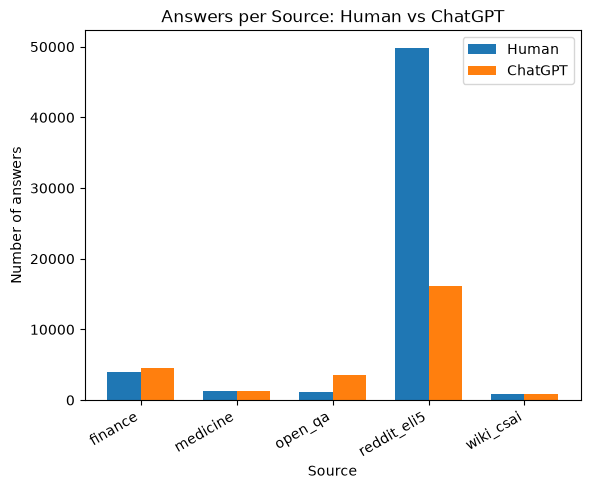

In [24]:
import numpy as np

counts = data.groupby(["source", "label"]).size().unstack(fill_value=0)
sources = counts.index.tolist()
x = np.arange(len(sources))
width = 0.35

plt.figure()
plt.bar(x - width / 2, counts[0], width, label="Human")
plt.bar(x + width / 2, counts[1], width, label="ChatGPT")
plt.xticks(x, sources, rotation=30, ha="right")
plt.xlabel("Source")
plt.ylabel("Number of answers")
plt.title("Answers per Source: Human vs ChatGPT")
plt.legend()
plt.savefig("../Visualizations/category_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

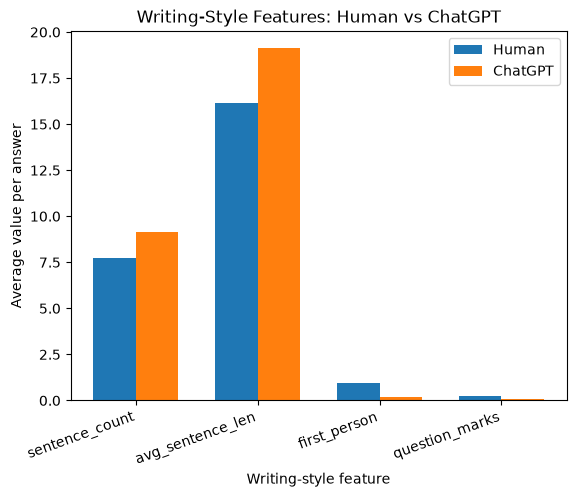

In [25]:
features = ["sentence_count", "avg_sentence_len", "first_person", "question_marks"]
means = data.groupby("label")[features].mean()
x = np.arange(len(features))
width = 0.35

plt.figure()
plt.bar(x - width / 2, means.loc[0], width, label="Human")
plt.bar(x + width / 2, means.loc[1], width, label="ChatGPT")
plt.xticks(x, features, rotation=20, ha="right")
plt.xlabel("Writing-style feature")
plt.ylabel("Average value per answer")
plt.title("Writing-Style Features: Human vs ChatGPT")
plt.legend()
plt.savefig("../Visualizations/trend_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

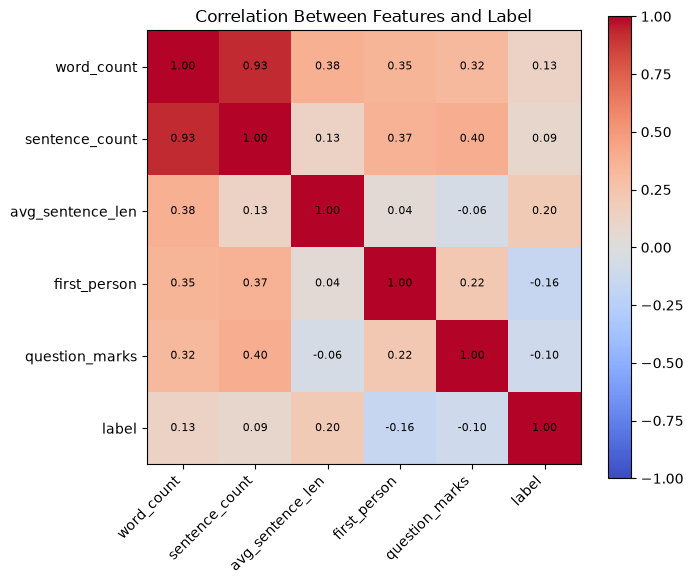

In [26]:
cols = ["word_count", "sentence_count", "avg_sentence_len", "first_person", "question_marks", "label"]
corr = data[cols].corr()

plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(cols)), cols, rotation=45, ha="right")
plt.yticks(range(len(cols)), cols)
plt.title("Correlation Between Features and Label")
for i in range(len(cols)):
    for j in range(len(cols)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.savefig("../Visualizations/correlation_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

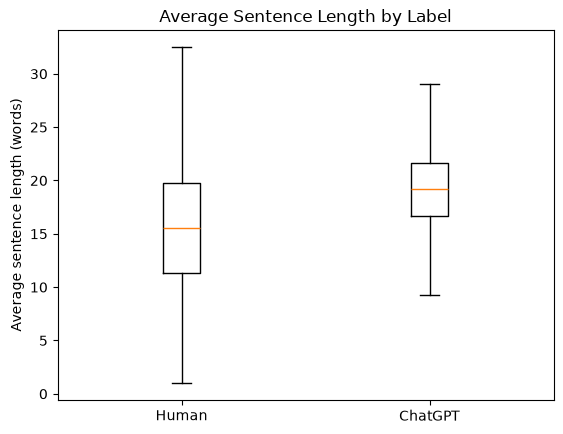

In [27]:
human_len = data[data["label"] == 0]["avg_sentence_len"]
ai_len = data[data["label"] == 1]["avg_sentence_len"]

plt.figure()
plt.boxplot([human_len, ai_len], showfliers=False, tick_labels=["Human", "ChatGPT"])
plt.ylabel("Average sentence length (words)")
plt.title("Average Sentence Length by Label")
plt.show()

## 6. Final Dataset Preparation

We fix leftover spacing artifacts and remove the giveaway phrase "As an AI language model", drop very short answers (fewer than 20 words) and duplicates, then balance the two classes so the final dataset has an equal number of Human and ChatGPT answers.

In [28]:
data["answer"] = data["answer"].str.replace(r"\s+([?.!,])", r"\1", regex=True)
data["answer"] = data["answer"].str.replace(r"\s+n't", "n't", regex=True)
data["answer"] = data["answer"].str.replace("As an AI language model, ", "", case=False, regex=False)

print("Giveaway phrases left:", data["answer"].str.contains("as an ai language model", case=False).sum())

Giveaway phrases left: 0


In [29]:
data = data[data["word_count"] >= 20]
data = data.drop_duplicates(subset=["answer"])

print(data["label"].value_counts())

label
0    49018
1    26173
Name: count, dtype: int64


In [30]:
human = data[data["label"] == 0]
ai = data[data["label"] == 1]

n = min(len(human), len(ai))
final = pd.concat([human.sample(n, random_state=42), ai.sample(n, random_state=42)])
final = final.sample(frac=1, random_state=42)

print(final["label"].value_counts())

label
0    26173
1    26173
Name: count, dtype: int64


In [31]:
final = final[["answer", "label", "source", "question"]]
final.to_csv("../Dataset/cleaned_dataset.csv", index=False)

check = pd.read_csv("../Dataset/cleaned_dataset.csv")
print(check.shape)
print(check["label"].value_counts())
print(check.isnull().sum())

(52346, 4)
label
0    26173
1    26173
Name: count, dtype: int64
answer      0
label       0
source      0
question    0
dtype: int64


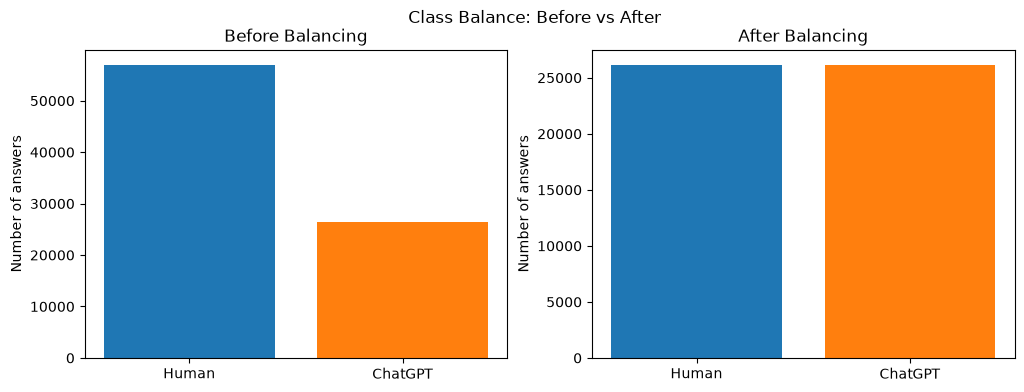

In [33]:
before_counts = pd.Series({"Human": 57019, "ChatGPT": 26381})
after_counts = final["label"].value_counts().sort_index()
after_counts.index = ["Human", "ChatGPT"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(before_counts.index, before_counts.values, color=["tab:blue", "tab:orange"])
axes[0].set_title("Before Balancing")
axes[0].set_ylabel("Number of answers")

axes[1].bar(after_counts.index, after_counts.values, color=["tab:blue", "tab:orange"])
axes[1].set_title("After Balancing")
axes[1].set_ylabel("Number of answers")

plt.suptitle("Class Balance: Before vs After")
plt.show()

## 7. Key Findings

- ChatGPT answers are longer (median 174 words vs 83 for human) and much more consistent in length
- Humans use first-person words (I, me, my) about 4.5 times more often (0.95 vs 0.21 per answer)
- Humans ask more questions inside answers (0.22 vs 0.07 question marks per answer)
- ChatGPT writes longer sentences (19.1 vs 16.1 words per sentence)
- Final dataset: 52,346 answers, balanced 50/50, saved as `cleaned_dataset.csv`